In [60]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [61]:
class Batsman(TypedDict):
    name:str
    runs:int
    balls:int
    sixes:int
    fours:int
    sr:float
    bpb:float
    bp:float
    summary:str

In [62]:
def strikeRate(state:Batsman):
    sr=(state["runs"]/state["balls"])*100
    return {"sr":sr}

In [63]:
def ballsPerBoundary(state:Batsman):
    bpb=state["balls"]/(state["fours"]+state["sixes"])
    return {"bpb":bpb}

In [64]:
def boundaryPercentage(state:Batsman):
    bp=((state["fours"]*4+state["sixes"]*6)/(state["runs"]))*100
    return {"bp":bp}

In [65]:
def summary(state:Batsman):
    print(state)
    summary=f"""
    Batsman Name: {state["name"]}
    Runs Scored: {state["runs"]}
    Balls Faced: {state["balls"]}
    Number of Fours: {state["fours"]}
    Number of Sixes: {state["sixes"]}
    Strike Rate: {state["sr"]}
    Balls Per Boundary: {state["bpb"]}
    Boundary Percentage: {state["bp"]}
    """
    return {"summary":summary}

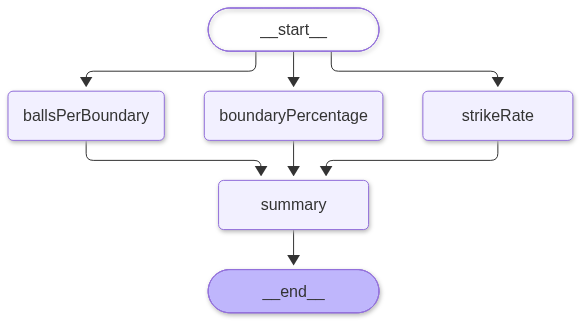

In [66]:
graph=StateGraph(Batsman)

graph.add_node("strikeRate",strikeRate)
graph.add_node("ballsPerBoundary",ballsPerBoundary)
graph.add_node("boundaryPercentage",boundaryPercentage)
graph.add_node("summary",summary)

graph.add_edge(START,"strikeRate")
graph.add_edge(START,"ballsPerBoundary")
graph.add_edge(START,"boundaryPercentage")
graph.add_edge("strikeRate","summary")
graph.add_edge("ballsPerBoundary","summary")
graph.add_edge("boundaryPercentage","summary")
workflow=graph.compile()
workflow


In [67]:
initial_state={"name":"Virat","runs":100,"balls":60,"sixes":4,"fours":8,"sr":0.0,"bpb":0.0,"bp":0.0,"summary":""}
final_state=workflow.invoke(initial_state)
final_state

{'name': 'Virat', 'runs': 100, 'balls': 60, 'sixes': 4, 'fours': 8, 'sr': 166.66666666666669, 'bpb': 5.0, 'bp': 56.00000000000001, 'summary': ''}


{'name': 'Virat',
 'runs': 100,
 'balls': 60,
 'sixes': 4,
 'fours': 8,
 'sr': 166.66666666666669,
 'bpb': 5.0,
 'bp': 56.00000000000001,
 'summary': '\n    Batsman Name: Virat\n    Runs Scored: 100\n    Balls Faced: 60\n    Number of Fours: 8\n    Number of Sixes: 4\n    Strike Rate: 166.66666666666669\n    Balls Per Boundary: 5.0\n    Boundary Percentage: 56.00000000000001\n    '}